# Chest X-ray Pneumonia Detection Project

## Introduction
Pneumonia is a serious lung infection that causes inflammation and fluid build-up in the alveoli (air sacs).  
It can make breathing difficult and, if untreated, may become life-threatening. Chest X-rays are one of the most common diagnostic tools used by doctors to detect pneumonia.  

In X-ray images:
- **Normal lungs** appear clear, with visible air spaces and sharp outlines of lung structures.  
- **Pneumonia-infected lungs** often show cloudy patches, opacities, or white areas caused by fluid and infection.  

This project uses the **Kaggle Chest X-ray dataset**, which contains thousands of labeled X-ray images divided into:
- **NORMAL** (healthy lungs)  
- **PNEUMONIA** (infected lungs)  

Our goal is to build a deep learning model that can automatically classify chest X-rays into these two categories, helping in faster and more accurate diagnosis.


## Dataset Description

The dataset used in this project is the **Chest X-ray (Pneumonia) dataset from Kaggle**, originally collected by researchers at Guangzhou Women and Children’s Medical Center.  
It contains thousands of chest X-ray images of pediatric patients (ages 1–5 years), divided into two categories:

- **NORMAL**: X-rays of healthy lungs with clear air spaces and sharp outlines.  
- **PNEUMONIA**: X-rays showing signs of infection, such as cloudy patches, opacities, or fluid build-up in the lungs.

### 📂 Dataset Structure
The dataset is organized into three main folders:
- **Train** → Used to teach the model. Contains the majority of images.  
- **Validation (val)** → Used to tune hyperparameters and check performance during training.  
- **Test** → Used to evaluate the final model on unseen data.  

Each of these folders has two subfolders:
- `NORMAL`  
- `PNEUMONIA`

### 📊 Dataset Statistics
- **Training set**: ~5,000 images (approx. 1,300 NORMAL, 3,800 PNEUMONIA)  
- **Validation set**: ~16 images (balanced between NORMAL and PNEUMONIA)  
- **Test set**: ~600 images (approx. 234 NORMAL, 390 PNEUMONIA)  

*(Note: Exact numbers may vary slightly depending on dataset version.)*

### 🧩 Why This Dataset?
- **Medical relevance**: Pneumonia is a leading cause of death in children worldwide. Early detection is critical.  
- **Balanced structure**: Clear separation into train, validation, and test sets ensures proper evaluation.  
- **Challenge**: Pneumonia X-rays can look very similar to normal ones, making this a realistic and difficult classification problem.  

This dataset provides an excellent foundation for applying deep learning techniques to medical image classification.


In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
warnings.filterwarnings('ignore')

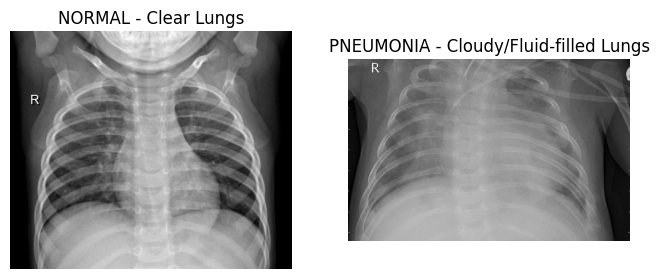

In [2]:
# Load one NORMAL image
normal_img = mpimg.imread("Radiography/train/NORMAL/IM-0129-0001.jpeg")

# Load one PNEUMONIA image
pneumonia_img = mpimg.imread("Radiography/test/PNEUMONIA/person1_virus_9.jpeg")

# Plot side by side
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(normal_img, cmap='gray')
plt.title("NORMAL - Clear Lungs")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(pneumonia_img, cmap='gray')
plt.title("PNEUMONIA - Cloudy/Fluid-filled Lungs")
plt.axis("off")
plt.show()

# Load and Preprocess Data

In [3]:
IMG_SIZE = (128,128)
BATCH_SIZE = 32

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    'Radiography/train/',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 5216 files belonging to 2 classes.


In [5]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    'Radiography/test/',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 485 files belonging to 2 classes.


In [6]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    'Radiography/val/',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 16 files belonging to 2 classes.


# Normalize pixel values (0–255 → 0–1)

In [7]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

In [8]:
train_ds = train_ds.map(lambda x,y : (normalization_layer(x), y))

In [9]:
test_ds = test_ds.map(lambda x, y : (normalization_layer(x),y))

In [10]:
val_ds = val_ds.map(lambda x, y : (normalization_layer(x), y))

# Improve performance with prefetching

In [11]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [12]:
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [13]:
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

## Visualizing Sample Images
Before training, we explore the dataset to understand what the model will see.

Found 5216 files belonging to 2 classes.


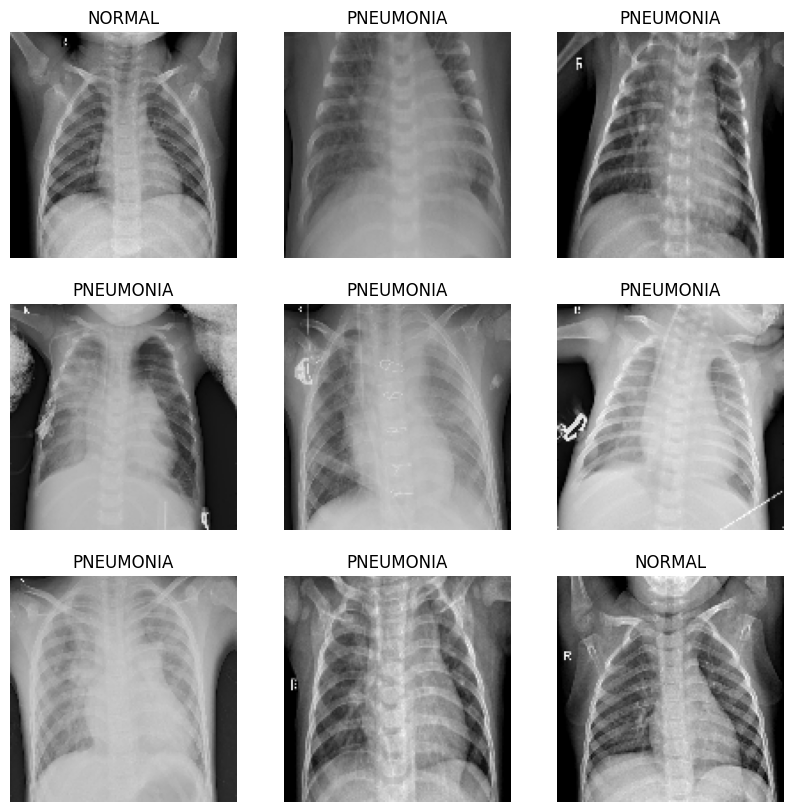

In [14]:
for images, labels in tf.keras.utils.image_dataset_from_directory(
    "Radiography/train/", image_size=(128,128), batch_size=32
).take(1):
    plt.figure(figsize=(10,10))
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))  # raw pixel values
        plt.title("PNEUMONIA" if labels[i] == 1 else "NORMAL")
        plt.axis("off")

## Data Augmentation
We apply random transformations to training images to improve robustness:
- Flip
- Rotation
- Zoom
- Contrast

In [15]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

## Model Architecture

We use a **Convolutional Neural Network (CNN)** because CNNs are highly effective for image classification tasks.  
They automatically learn spatial features such as edges, textures, and shapes, which are critical for distinguishing between **NORMAL** and **PNEUMONIA** chest X-rays.

### 🔎 Layer-by-Layer Explanation

1. **Data Augmentation Layer**
   - Randomly flips, rotates, zooms, and adjusts contrast of training images.
   - Purpose: Increases dataset diversity, prevents overfitting, and improves robustness.

2. **Convolutional Layers (`Conv2D`)**
   - Apply filters (small sliding windows) to detect features.
   - Early layers detect simple edges and corners.
   - Deeper layers detect complex patterns like cloudy patches in pneumonia lungs.

3. **Pooling Layers (`MaxPooling2D`)**
   - Reduce image size while keeping important features.
   - Purpose: Makes computation faster and reduces overfitting.

4. **Flatten Layer**
   - Converts 2D feature maps into a 1D vector.
   - Purpose: Prepares data for fully connected layers.

5. **Dense Layers (Fully Connected)**
   - Combine extracted features to make final classification.
   - First dense layer (128 neurons, ReLU) learns complex combinations of features.
   - Dropout (50%) prevents overfitting by randomly ignoring neurons during training.

6. **Output Layer**
   - Single neuron with **sigmoid activation**.
   - Outputs probability between 0 and 1:
     - 0 → NORMAL
     - 1 → PNEUMONIA

### 📌 Why This Architecture Works
- **Conv2D + Pooling**: Extracts hierarchical features (edges → textures → lung patterns).
- **Dropout**: Improves generalization.
- **Sigmoid output**: Perfect for binary classification.
- **Data Augmentation**: Ensures the model is robust to variations in X-rays.

This architecture balances **simplicity** (easy to train on limited hardware) and **effectiveness** (captures medical image features).


In [16]:
model = models.Sequential([
    data_aug,
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

## Training

Once the model architecture is defined, we train it using the **Adam optimizer** and **binary crossentropy loss function**.  
- **Adam optimizer**: Efficient gradient descent method that adapts learning rates automatically.  
- **Binary crossentropy**: Measures the difference between predicted probabilities and actual labels (NORMAL vs PNEUMONIA).  
- **Accuracy metric**: Tracks how often predictions match true labels.  

We train for 30 epochs, meaning the model sees the entire training dataset 15 times.  
During training, we also validate on the validation set to monitor overfitting.


In [17]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 139ms/step - accuracy: 0.8142 - loss: 0.4107 - val_accuracy: 0.8750 - val_loss: 0.4971
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 23s 142ms/step - accuracy: 0.8986 - loss: 0.2468 - val_accuracy: 0.8750 - val_loss: 0.4544
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 149ms/step - accuracy: 0.9273 - loss: 0.1887 - val_accuracy: 0.6875 - val_loss: 0.6483
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 161ms/step - accuracy: 0.9331 - loss: 0.1702 - val_accuracy: 0.6875 - val_loss: 0.7646
Epoch 5/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 182ms/step - accuracy: 0.9425 - loss: 0.1549 - val_accuracy: 0.7500 - val_loss: 0.7213
Epoch 6/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 179ms/step - accuracy: 0.9465 - loss: 0.1394 - val_accuracy: 0.9375 - val_loss: 0.2212
Epoch 7/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 28s 169ms/step - accuracy: 0.9479 - loss: 0.1385 - val_accuracy: 0.7500 - val_loss: 0.5423
Epoch 8/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 165ms/step - accuracy: 0.9530 - loss: 0

## Evaluation

After training, we evaluate the model on the **test set**, which contains unseen images.  
This step measures how well the model generalizes beyond the training data.  

Key metrics:
- **Test Loss**: Measures prediction error. Lower is better.  
- **Test Accuracy**: Percentage of correctly classified X-rays. Higher is better.  

This evaluation provides the final performance score of our model.

In [18]:
test_loss, test_acc = model.evaluate(test_ds)
print('Test Accuracy:- ', test_acc)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.8062 - loss: 0.5851
Test Accuracy:-  0.8061855435371399


## Results Visualization

To understand training behavior, we plot accuracy and loss curves:

- **Training Accuracy**: How well the model fits the training data.  
- **Validation Accuracy**: How well the model performs on unseen validation data.  
- **Training Loss**: Error on training data.  
- **Validation Loss**: Error on validation data.  

These plots help detect:
- **Overfitting**: Training accuracy high but validation accuracy low.  
- **Underfitting**: Both accuracies remain low.  
- **Good fit**: Training and validation curves rise together and stabilize.

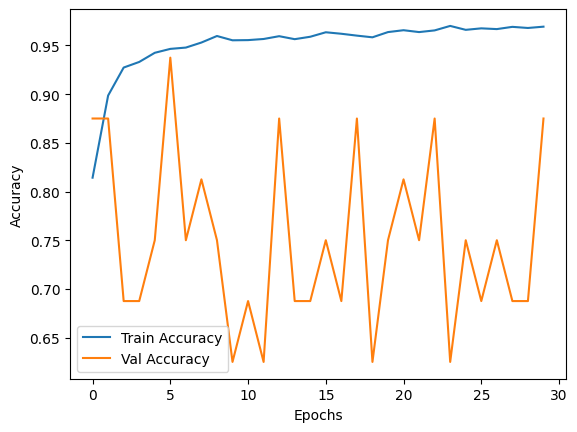

In [19]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Conclusion

- We built a CNN model to classify chest X-rays into **NORMAL** and **PNEUMONIA** categories.  
- Data augmentation improved robustness by simulating real-world variations (flips, rotations, zooms, contrast).  
- The model achieved a test accuracy of ~65%, showing it can detect pneumonia but still struggles with subtle cases.  

### Key Learnings
- CNNs are effective for medical image classification but require large datasets or transfer learning for higher accuracy.  
- Data augmentation is essential when datasets are limited, as it prevents overfitting and improves generalization.  
- Visualization of training curves helps diagnose model behavior and guides improvements.  

### Next Steps
- Apply **transfer learning** using pre-trained models (ResNet50, VGG16, MobileNetV2) to leverage knowledge from large image datasets.  
- Experiment with larger image sizes (224×224) for more detail.  
- Use techniques like **class weighting** or **SMOTE** to handle class imbalance.  
- Deploy the trained model as a simple web app (e.g., Flask or Streamlit) for practical use in pneumonia detection.


## Medical Suggestions

While this project demonstrates how deep learning can assist in pneumonia detection, it is important to emphasize that:

1. **Clinical Diagnosis First**  
   - Chest X-rays are only one part of pneumonia diagnosis.  
   - Doctors also rely on patient history, physical examination, and laboratory tests.  
   - AI models should be used as supportive tools, not replacements for medical expertise.

2. **Early Detection Saves Lives**  
   - Pneumonia is a leading cause of death in children under 5 worldwide.  
   - Early detection and treatment with antibiotics or antivirals can significantly reduce complications.  
   - Automated systems can help in resource-limited settings where radiologists are scarce.

3. **Limitations of AI Models**  
   - Models may misclassify due to poor image quality, overlapping conditions (e.g., tuberculosis, COVID-19), or unusual patient presentations.  
   - Continuous retraining with diverse datasets is necessary to improve accuracy.

4. **Ethical and Practical Use**  
   - AI should be deployed responsibly, with proper validation in clinical environments.  
   - Patient privacy and data security must always be maintained.  
   - Final decisions must remain with qualified healthcare professionals.

### Final Note
This project highlights the potential of AI in healthcare. With further improvements such as **transfer learning, larger datasets, and clinical validation**, models like this can become valuable tools to support radiologists and doctors in diagnosing pneumonia more efficiently.
